In [1]:
"""
STEP 3: Local Models
===============================================
Approach:
- Train ONE model per z-height (50 models)
- Each model has x as INPUT feature
- Input:  [x, U_ref, alpha_inlet, delta_inlet] → 4 features
- Output: U_x at that specific z-height
- Training: 88 points per model (11 x-locations × 8 cases)

Validation:
- Option 1: K-fold cross-validation (standard)
- Option 2: Spatial test (hold out x-locations)
- Option 3: Case test (hold out inlet conditions)¨

Models:
- LNU: Linear (4 inputs + bias = 5 params)
- QNU: Quadratic (14 params with interactions)
- MLP: Neural network (~50-100 params)

Author: Vit Uhlir
"""

from setup_paths import PROCESSED_DATA_DIR, RESULTS_DIR, FIGURES_DIR, REPORTS_DIR  
import sys

import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy import stats
# from scipy.interpolate import interp1d
import warnings
warnings.filterwarnings('ignore')



In [2]:
# ============================================================================
# CONFIGURATION
# ============================================================================

INPUT_FILE = PROCESSED_DATA_DIR / 'all_cases_data.pkl'
OUTPUT_DIR = RESULTS_DIR

# Cube geometry
H_CUBE = 0.015  # meters

# Validation strategy
VALIDATION_MODE = 'spatial'  # Options: 'cv', 'spatial', 'case'

# Model settings
RANDOM_STATE = 42

# Plot settings
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10

print("="*80)
print(" "*15 + "STEP 3: LOCAL MODELS (VERTICAL STRATIFICATION)")
print("="*80)
print(f"\nStrategy: One model per z-height, with x as input")
print(f"Input features: [x, U_ref, alpha_inlet, delta_inlet]")
print(f"Validation mode: {VALIDATION_MODE}")                         # 8 cases

               STEP 3: LOCAL MODELS (VERTICAL STRATIFICATION)

Strategy: One model per z-height, with x as input
Input features: [x, U_ref, alpha_inlet, delta_inlet]
Validation mode: spatial


In [3]:
# ============================================================================
# LOAD DATA
# ============================================================================

print(f"\n{'='*80}")
print("LOADING DATA")
print("="*80)

# Load CFD data
with open(INPUT_FILE, 'rb') as f:
    all_cases_data = pickle.load(f)

print(f"✓ Loaded {len(all_cases_data)} cases")

# Extract inlet parameters
inlet_parameters = {}
for case_id, case_data in all_cases_data.items():
    if 0.0 in case_data['profiles']:
        profile = case_data['profiles'][0.0]
        z = profile['z']
        U_x = profile['U_x']
        
        # Simple power law fit
        mask = (z > 0) & (U_x > 0)
        if mask.sum() >= 3:
            z_clean = z[mask]
            U_clean = U_x[mask]
            z_ref = z_clean[0] if z_clean[0] > 0 else 0.001
            log_z = np.log(z_clean / z_ref)
            log_U = np.log(U_clean)
            coeffs = np.polyfit(log_z, log_U, 1)
            alpha = coeffs[0]
        else:
            alpha = 0.01
        
        # BL thickness
        U_max = U_x.max()
        idx = np.where(U_x >= 0.99 * U_max)[0]
        delta = z[idx[0]] if len(idx) > 0 else z.max()
        
        inlet_parameters[case_id] = {
            'U_ref': case_data['U_ref'],
            'profile_type': case_data['profile_type'],
            'profile_name': case_data['profile_name'],
            'alpha_inlet': alpha,
            'delta_inlet': delta,
        }

print(f"✓ Extracted inlet parameters for {len(inlet_parameters)} cases")



LOADING DATA
✓ Loaded 8 cases
✓ Extracted inlet parameters for 8 cases


In [4]:
# ============================================================================
# DEFINE SPATIAL LOCATIONS
# ============================================================================

print(f"\n{'='*80}")
print("SPATIAL LOCATION SELECTION")
print("="*80)

# Get all available x-locations
all_x_locations = sorted(list(set([x for case_data in all_cases_data.values() 
                                     for x in case_data['profiles'].keys()])))

print(f"\nAvailable x-locations: {len(all_x_locations)}")
print(f"  {[f'{x:.4f}' for x in all_x_locations]}")

# Select training and test locations
if VALIDATION_MODE == 'spatial':
    # TRAINING: Select 8 representative locations    - arbitrary (select as you wish)
    x_train = [0.0, 0.0375, 0.075, 0.0903, 0.105, 0.12, 0.15, 0.315]
    
    # TESTING: Hold out 3 locations for spatial interpolation test
    x_test = [0.0650, 0.0825, 0.1350]
    
    print(f"\n✓ Training x-locations: {len(x_train)}")
    print(f"  {[f'{x:.4f}' for x in x_train]}")
    print(f"\n✓ Testing x-locations: {len(x_test)} (spatial generalization)")
    print(f"  {[f'{x:.4f}' for x in x_test]}")
    
else:
    # Use all locations for CV or case-based validation
    x_train = all_x_locations
    x_test = []
    print(f"\n✓ Using all {len(x_train)} x-locations for training")



SPATIAL LOCATION SELECTION

Available x-locations: 11
  ['0.0000', '0.0375', '0.0650', '0.0750', '0.0825', '0.0903', '0.1050', '0.1200', '0.1350', '0.1500', '0.3150']

✓ Training x-locations: 8
  ['0.0000', '0.0375', '0.0750', '0.0903', '0.1050', '0.1200', '0.1500', '0.3150']

✓ Testing x-locations: 3 (spatial generalization)
  ['0.0650', '0.0825', '0.1350']


In [5]:
# ============================================================================
# SELECT Z-HEIGHTS
# ============================================================================

print(f"\n{'='*80}")
print("VERTICAL HEIGHT SELECTION")
print("="*80)

# Get typical z-range from first case
first_case = list(all_cases_data.values())[0]
first_profile = first_case['profiles'][0.0]
z_min = first_profile['z'].min()
z_max = first_profile['z'].max()

print(f"\nAvailable z-range: [{z_min:.4f}, {z_max:.4f}] m")
print(f"Number of samples within z-range: {len(first_profile['z'])}")

# Option 1: Use many heights (dense sampling)
# n_z_heights = 30                                                   # Select number of points
# z_heights = np.linspace(z_min + 0.001, z_max - 0.001, n_z_heights) # Use the selected number
z_heights = first_case['profiles'][0.0]['z']                       # Use all available

print(f"\n✓ Selected {len(z_heights)} z-heights for training")
print(f"  Range: [{z_heights[0]:.4f}, {z_heights[-1]:.4f}] m")
print(f"  Spacing: {(z_heights[1]-z_heights[0])*1000:.2f} mm")



VERTICAL HEIGHT SELECTION

Available z-range: [0.0003, 0.0481] m
Number of samples within z-range: 55

✓ Selected 55 z-heights for training
  Range: [0.0003, 0.0481] m
  Spacing: 0.62 mm


In [6]:
# ============================================================================
# EXTRACT ALL UNIQUE Z-POINTS FROM CFD DATA
# ============================================================================

print(f"\n{'='*80}")
print("EXTRACTING UNIQUE Z-POINTS FROM CFD")
print("="*80)

# Collect all z-points from all profiles
all_z_points = set()
z_min_global = float('inf')
z_max_global = float('-inf')

for case_data in all_cases_data.values():
    for x_loc, profile in case_data['profiles'].items():
        if x_loc in x_train:  # Only from training locations
            z = profile['z']
            all_z_points.update(z)
            z_min_global = min(z_min_global, z.min())
            z_max_global = max(z_max_global, z.max())

# Convert to sorted array
z_heights = np.array(sorted(all_z_points))

print(f"\n✓ Found {len(z_heights)} unique z-points across all training profiles")
print(f"  Range: [{z_heights[0]:.6f}, {z_heights[-1]:.6f}] m")
print(f"  Average spacing: {np.mean(np.diff(z_heights))*1000:.3f} mm")



EXTRACTING UNIQUE Z-POINTS FROM CFD

✓ Found 108 unique z-points across all training profiles
  Range: [0.000312, 0.048125] m
  Average spacing: 0.447 mm


In [7]:
# ============================================================================
# EXTRACT TRAINING DATA
# ============================================================================

print(f"\n{'='*80}")
print("EXTRACTING TRAINING DATA (Exact CFD Points Only)")
print("="*80)

# Create training dataset for each z-height
training_data = {}

for z_target in z_heights:
    X_data = []
    y_data = []
    
    for case_id, case_data in all_cases_data.items():
        inlet_params = inlet_parameters[case_id]
        
        for x_loc in x_train:
            if x_loc in case_data['profiles']:
                profile = case_data['profiles'][x_loc]
                z_profile = profile['z']
                U_profile = profile['U_x']
                
                # Find EXACT match (no interpolation!)
                # Allow small tolerance for floating point comparison   (find nearest points)
                matches = np.abs(z_profile - z_target) < 1e-10  # 0.0012500 
                
                if matches.any():
                    idx = np.where(matches)[0][0]
                    U_x = U_profile[idx]
                    
                    X_data.append([
                        x_loc,
                        inlet_params['U_ref'],
                        inlet_params['alpha_inlet'],
                        inlet_params['delta_inlet']
                    ])
                    y_data.append(U_x)
    
    if len(X_data) > 0:  # Only store if we have data
        training_data[z_target] = {
            'X': np.array(X_data),
            'y': np.array(y_data)
        }

# Remove z-heights with insufficient data
z_heights_original = len(z_heights)
z_heights = np.array([z for z in z_heights if z in training_data])

print(f"\n✓ Extracted training data for {len(z_heights)} z-heights")
print(f"  Removed {z_heights_original - len(z_heights)} z-heights with insufficient data")

# Check data distribution
data_counts = [len(training_data[z]['X']) for z in z_heights]
print(f"\nTraining points per z-height:")
print(f"  Min: {min(data_counts)}")
print(f"  Max: {max(data_counts)}")
print(f"  Mean: {np.mean(data_counts):.1f}")
print(f"  Expected max: {len(x_train)} x-locs × {len(inlet_parameters)} cases = {len(x_train) * len(inlet_parameters)}")

# Verify first z-height
if len(z_heights) > 0:
    train_points = len(training_data[z_heights[0]]['X'])
    print(f"\nFirst z-height ({z_heights[0]:.6f} m): {train_points} points")



EXTRACTING TRAINING DATA (Exact CFD Points Only)

✓ Extracted training data for 108 z-heights
  Removed 0 z-heights with insufficient data

Training points per z-height:
  Min: 8
  Max: 56
  Mean: 30.1
  Expected max: 8 x-locs × 8 cases = 64

First z-height (0.000312 m): 8 points


In [8]:
# ============================================================================
# TRAIN MODELS AT EACH Z-HEIGHT
# ============================================================================

print(f"\n{'='*80}")
print("TRAINING MODELS")
print("="*80)

models = {}
metrics = {}
feature_scaler = StandardScaler()

# Fit scaler on all training data
all_X = np.vstack([training_data[z]['X'] for z in z_heights])
feature_scaler.fit(all_X)

for i, z in enumerate(z_heights):
    if (i+1) % 10 == 0:
        print(f"\nTraining models at z-height {i+1}/{len(z_heights)} (z={z:.4f} m)...")
    
    X_train_z = training_data[z]['X']
    y_train_z = training_data[z]['y']
    
    # Scale features
    X_train_scaled = feature_scaler.transform(X_train_z)
    
    # ========================================================================
    # MODEL 1: LNU (Linear)
    # ========================================================================
    model_LNU = LinearRegression()
    model_LNU.fit(X_train_scaled, y_train_z)
    
    y_pred_LNU = model_LNU.predict(X_train_scaled)
    R2_LNU = r2_score(y_train_z, y_pred_LNU)
    RMSE_LNU = np.sqrt(mean_squared_error(y_train_z, y_pred_LNU))
    MAE_LNU = mean_absolute_error(y_train_z, y_pred_LNU)
    
    # Confidence intervals (95%)
    residuals_LNU = y_train_z - y_pred_LNU
    n = len(y_train_z)
    p = X_train_z.shape[1] + 1  # parameters
    dof = max(n - p, 1)
    t_stat = stats.t.ppf(0.975, dof)
    std_error_LNU = np.std(residuals_LNU)
    CI_LNU = t_stat * std_error_LNU * np.sqrt(1 + 1/n)
    
    # Cross-validation
    if VALIDATION_MODE == 'cv':
        cv_scores_LNU = cross_val_score(model_LNU, X_train_scaled, y_train_z, 
                                          cv=min(5, n), scoring='r2')
        cv_mean_LNU = cv_scores_LNU.mean()
        cv_std_LNU = cv_scores_LNU.std()
    else:
        cv_mean_LNU = R2_LNU
        cv_std_LNU = 0.0
    
    # ========================================================================
    # MODEL 2: QNU (Quadratic)
    # ========================================================================
    poly = PolynomialFeatures(degree=2, include_bias=False)
    X_train_poly = poly.fit_transform(X_train_scaled)
    
    model_QNU = LinearRegression()
    model_QNU.fit(X_train_poly, y_train_z)
    
    y_pred_QNU = model_QNU.predict(X_train_poly)
    R2_QNU = r2_score(y_train_z, y_pred_QNU)
    RMSE_QNU = np.sqrt(mean_squared_error(y_train_z, y_pred_QNU))
    MAE_QNU = mean_absolute_error(y_train_z, y_pred_QNU)
    
    # Confidence intervals
    residuals_QNU = y_train_z - y_pred_QNU
    p_qnu = X_train_poly.shape[1] + 1
    dof_qnu = max(n - p_qnu, 1)
    t_stat_qnu = stats.t.ppf(0.975, dof_qnu)
    std_error_QNU = np.std(residuals_QNU)
    CI_QNU = t_stat_qnu * std_error_QNU * np.sqrt(1 + 1/n)
    
    # Cross-validation
    if VALIDATION_MODE == 'cv':
        cv_scores_QNU = cross_val_score(model_QNU, X_train_poly, y_train_z,
                                          cv=min(5, n), scoring='r2')
        cv_mean_QNU = cv_scores_QNU.mean()
        cv_std_QNU = cv_scores_QNU.std()
    else:
        cv_mean_QNU = R2_QNU
        cv_std_QNU = 0.0
    
    # ========================================================================
    # MODEL 3: MLP (Neural Network)
    # ========================================================================
    model_MLP = MLPRegressor(
        hidden_layer_sizes=(20, 10),
        activation='relu',
        solver='lbfgs',
        max_iter=2000,
        random_state=RANDOM_STATE,
        alpha=0.001
    )
    model_MLP.fit(X_train_scaled, y_train_z)
    
    y_pred_MLP = model_MLP.predict(X_train_scaled)
    R2_MLP = r2_score(y_train_z, y_pred_MLP)
    RMSE_MLP = np.sqrt(mean_squared_error(y_train_z, y_pred_MLP))
    MAE_MLP = mean_absolute_error(y_train_z, y_pred_MLP)
    
    # Cross-validation
    if VALIDATION_MODE == 'cv':
        cv_scores_MLP = cross_val_score(model_MLP, X_train_scaled, y_train_z,
                                          cv=min(5, n), scoring='r2')
        cv_mean_MLP = cv_scores_MLP.mean()
        cv_std_MLP = cv_scores_MLP.std()
    else:
        cv_mean_MLP = R2_MLP
        cv_std_MLP = 0.0
    
    # ========================================================================
    # STORE MODELS AND METRICS
    # ========================================================================
    models[z] = {
        'LNU': model_LNU,
        'QNU': (model_QNU, poly),
        'MLP': model_MLP,
    }
    
    metrics[z] = {
        'LNU': {
            'R2': R2_LNU,
            'RMSE': RMSE_LNU,
            'MAE': MAE_LNU,
            'CI': CI_LNU,
            'CV_mean': cv_mean_LNU,
            'CV_std': cv_std_LNU,
            'n_params': p
        },
        'QNU': {
            'R2': R2_QNU,
            'RMSE': RMSE_QNU,
            'MAE': MAE_QNU,
            'CI': CI_QNU,
            'CV_mean': cv_mean_QNU,
            'CV_std': cv_std_QNU,
            'n_params': p_qnu
        },
        'MLP': {
            'R2': R2_MLP,
            'RMSE': RMSE_MLP,
            'MAE': MAE_MLP,
            'CI': np.nan,  # No analytical CI for MLP
            'CV_mean': cv_mean_MLP,
            'CV_std': cv_std_MLP,
            'n_params': sum([w.size for w in model_MLP.coefs_] + [b.size for b in model_MLP.intercepts_])
        }
    }

print(f"\n✓ Trained {len(z_heights)} × 3 = {len(z_heights)*3} models")



TRAINING MODELS

Training models at z-height 10/108 (z=0.0028 m)...

Training models at z-height 20/108 (z=0.0059 m)...

Training models at z-height 30/108 (z=0.0091 m)...

Training models at z-height 40/108 (z=0.0122 m)...

Training models at z-height 50/108 (z=0.0153 m)...

Training models at z-height 60/108 (z=0.0178 m)...

Training models at z-height 70/108 (z=0.0203 m)...

Training models at z-height 80/108 (z=0.0244 m)...

Training models at z-height 90/108 (z=0.0284 m)...

Training models at z-height 100/108 (z=0.0381 m)...

✓ Trained 108 × 3 = 324 models


In [9]:
# ============================================================================
# AGGREGATE METRICS
# ============================================================================

print(f"\n{'='*80}")
print("TRAINING PERFORMANCE SUMMARY")
print("="*80)

for model_name in ['LNU', 'QNU', 'MLP']:
    R2_values = [metrics[z][model_name]['R2'] for z in z_heights]
    RMSE_values = [metrics[z][model_name]['RMSE'] for z in z_heights]
    MAE_values = [metrics[z][model_name]['MAE'] for z in z_heights]
    
    print(f"\n{model_name}:")
    print(f"  R²:   {np.mean(R2_values):.4f} ± {np.std(R2_values):.4f}")
    print(f"  RMSE: {np.mean(RMSE_values):.4f} ± {np.std(RMSE_values):.4f} m/s")
    print(f"  MAE:  {np.mean(MAE_values):.4f} ± {np.std(MAE_values):.4f} m/s")
    print(f"  Params: {metrics[z_heights[0]][model_name]['n_params']}")



TRAINING PERFORMANCE SUMMARY

LNU:
  R²:   0.9914 ± 0.0270
  RMSE: 0.1056 ± 0.1026 m/s
  MAE:  0.0822 ± 0.0744 m/s
  Params: 5

QNU:
  R²:   0.9987 ± 0.0089
  RMSE: 0.0287 ± 0.0421 m/s
  MAE:  0.0226 ± 0.0304 m/s
  Params: 15

MLP:
  R²:   1.0000 ± 0.0000
  RMSE: 0.0038 ± 0.0028 m/s
  MAE:  0.0028 ± 0.0020 m/s
  Params: 321


In [10]:
# ============================================================================
# SPATIAL TEST (if applicable)
# ============================================================================

if VALIDATION_MODE == 'spatial' and len(x_test) > 0:
    print(f"\n{'='*80}")
    print("SPATIAL INTERPOLATION TEST")
    print("="*80)
    print(f"\nTesting on {len(x_test)} held-out x-locations...")
    
    spatial_metrics = {model_name: [] for model_name in ['LNU', 'QNU', 'MLP']}
    
    for z in z_heights:
        for model_name in ['LNU', 'QNU', 'MLP']:
            y_true_test = []
            y_pred_test = []
            
            for case_id, case_data in all_cases_data.items():
                inlet_params = inlet_parameters[case_id]
                
                for x_loc in x_test:
                    if x_loc in case_data['profiles']:
                        profile = case_data['profiles'][x_loc]
                        z_profile = profile['z']
                        U_profile = profile['U_x']
                        
                        # Find EXACT z-match (no interpolation!)
                        matches = np.abs(z_profile - z) < 1e-10
                        
                        if matches.any():
                            idx = np.where(matches)[0][0]
                            U_true = U_profile[idx]
                            
                            X_test_point = np.array([[
                                x_loc,
                                inlet_params['U_ref'],
                                inlet_params['alpha_inlet'],
                                inlet_params['delta_inlet']
                            ]])
                            X_test_scaled = feature_scaler.transform(X_test_point)
                            
                            if model_name == 'QNU':
                                model, poly = models[z][model_name]
                                X_test_poly = poly.transform(X_test_scaled)
                                U_pred = model.predict(X_test_poly)[0]
                            else:
                                model = models[z][model_name]
                                U_pred = model.predict(X_test_scaled)[0]
                            
                            y_true_test.append(U_true)
                            y_pred_test.append(U_pred)
            
            if len(y_true_test) > 0:
                R2_test = r2_score(y_true_test, y_pred_test)
                RMSE_test = np.sqrt(mean_squared_error(y_true_test, y_pred_test))
                spatial_metrics[model_name].append({
                    'z': z,
                    'R2': R2_test,
                    'RMSE': RMSE_test
                })
    
    print(f"\n✓ Spatial test complete")
    print(f"\nSpatial Test Performance:")
    for model_name in ['LNU', 'QNU', 'MLP']:
        if len(spatial_metrics[model_name]) > 0:
            R2_test = np.mean([m['R2'] for m in spatial_metrics[model_name]])
            RMSE_test = np.mean([m['RMSE'] for m in spatial_metrics[model_name]])
            print(f"  {model_name}: R²={R2_test:.4f}, RMSE={RMSE_test:.4f} m/s")
        else:
            print(f"  {model_name}: No test data available")



SPATIAL INTERPOLATION TEST

Testing on 3 held-out x-locations...

✓ Spatial test complete

Spatial Test Performance:
  LNU: R²=0.8447, RMSE=0.3509 m/s
  QNU: R²=0.8484, RMSE=0.2829 m/s
  MLP: R²=0.8455, RMSE=0.2661 m/s


In [11]:
# ============================================================================
# PROFILE RECONSTRUCTION EXAMPLE
# ============================================================================

print(f"\n{'='*80}")
print("PROFILE RECONSTRUCTION EXAMPLE")
print("="*80)

# Select test case
x_test_loc = 0.105  # Wake region
U_ref_test = 3.0
alpha_test = 0.14
delta_test = 0.025

print(f"\nPredicting profile at x={x_test_loc} m")
print(f"  Inlet conditions: U_ref={U_ref_test}, α={alpha_test:.3f}, δ={delta_test*1000:.1f}mm")

# Predict at all z-heights
profiles_predicted = {model_name: [] for model_name in ['LNU', 'QNU', 'MLP']}

for z in z_heights:
    X_pred = np.array([[x_test_loc, U_ref_test, alpha_test, delta_test]])
    X_pred_scaled = feature_scaler.transform(X_pred)
    
    for model_name in ['LNU', 'QNU', 'MLP']:
        if model_name == 'QNU':
            model, poly = models[z][model_name]
            X_pred_poly = poly.transform(X_pred_scaled)
            U_pred = model.predict(X_pred_poly)[0]
        else:
            model = models[z][model_name]
            U_pred = model.predict(X_pred_scaled)[0]
        
        profiles_predicted[model_name].append(U_pred)

print(f"\n✓ Reconstructed complete vertical profile")



PROFILE RECONSTRUCTION EXAMPLE

Predicting profile at x=0.105 m
  Inlet conditions: U_ref=3.0, α=0.140, δ=25.0mm

✓ Reconstructed complete vertical profile



CREATING VISUALIZATIONS


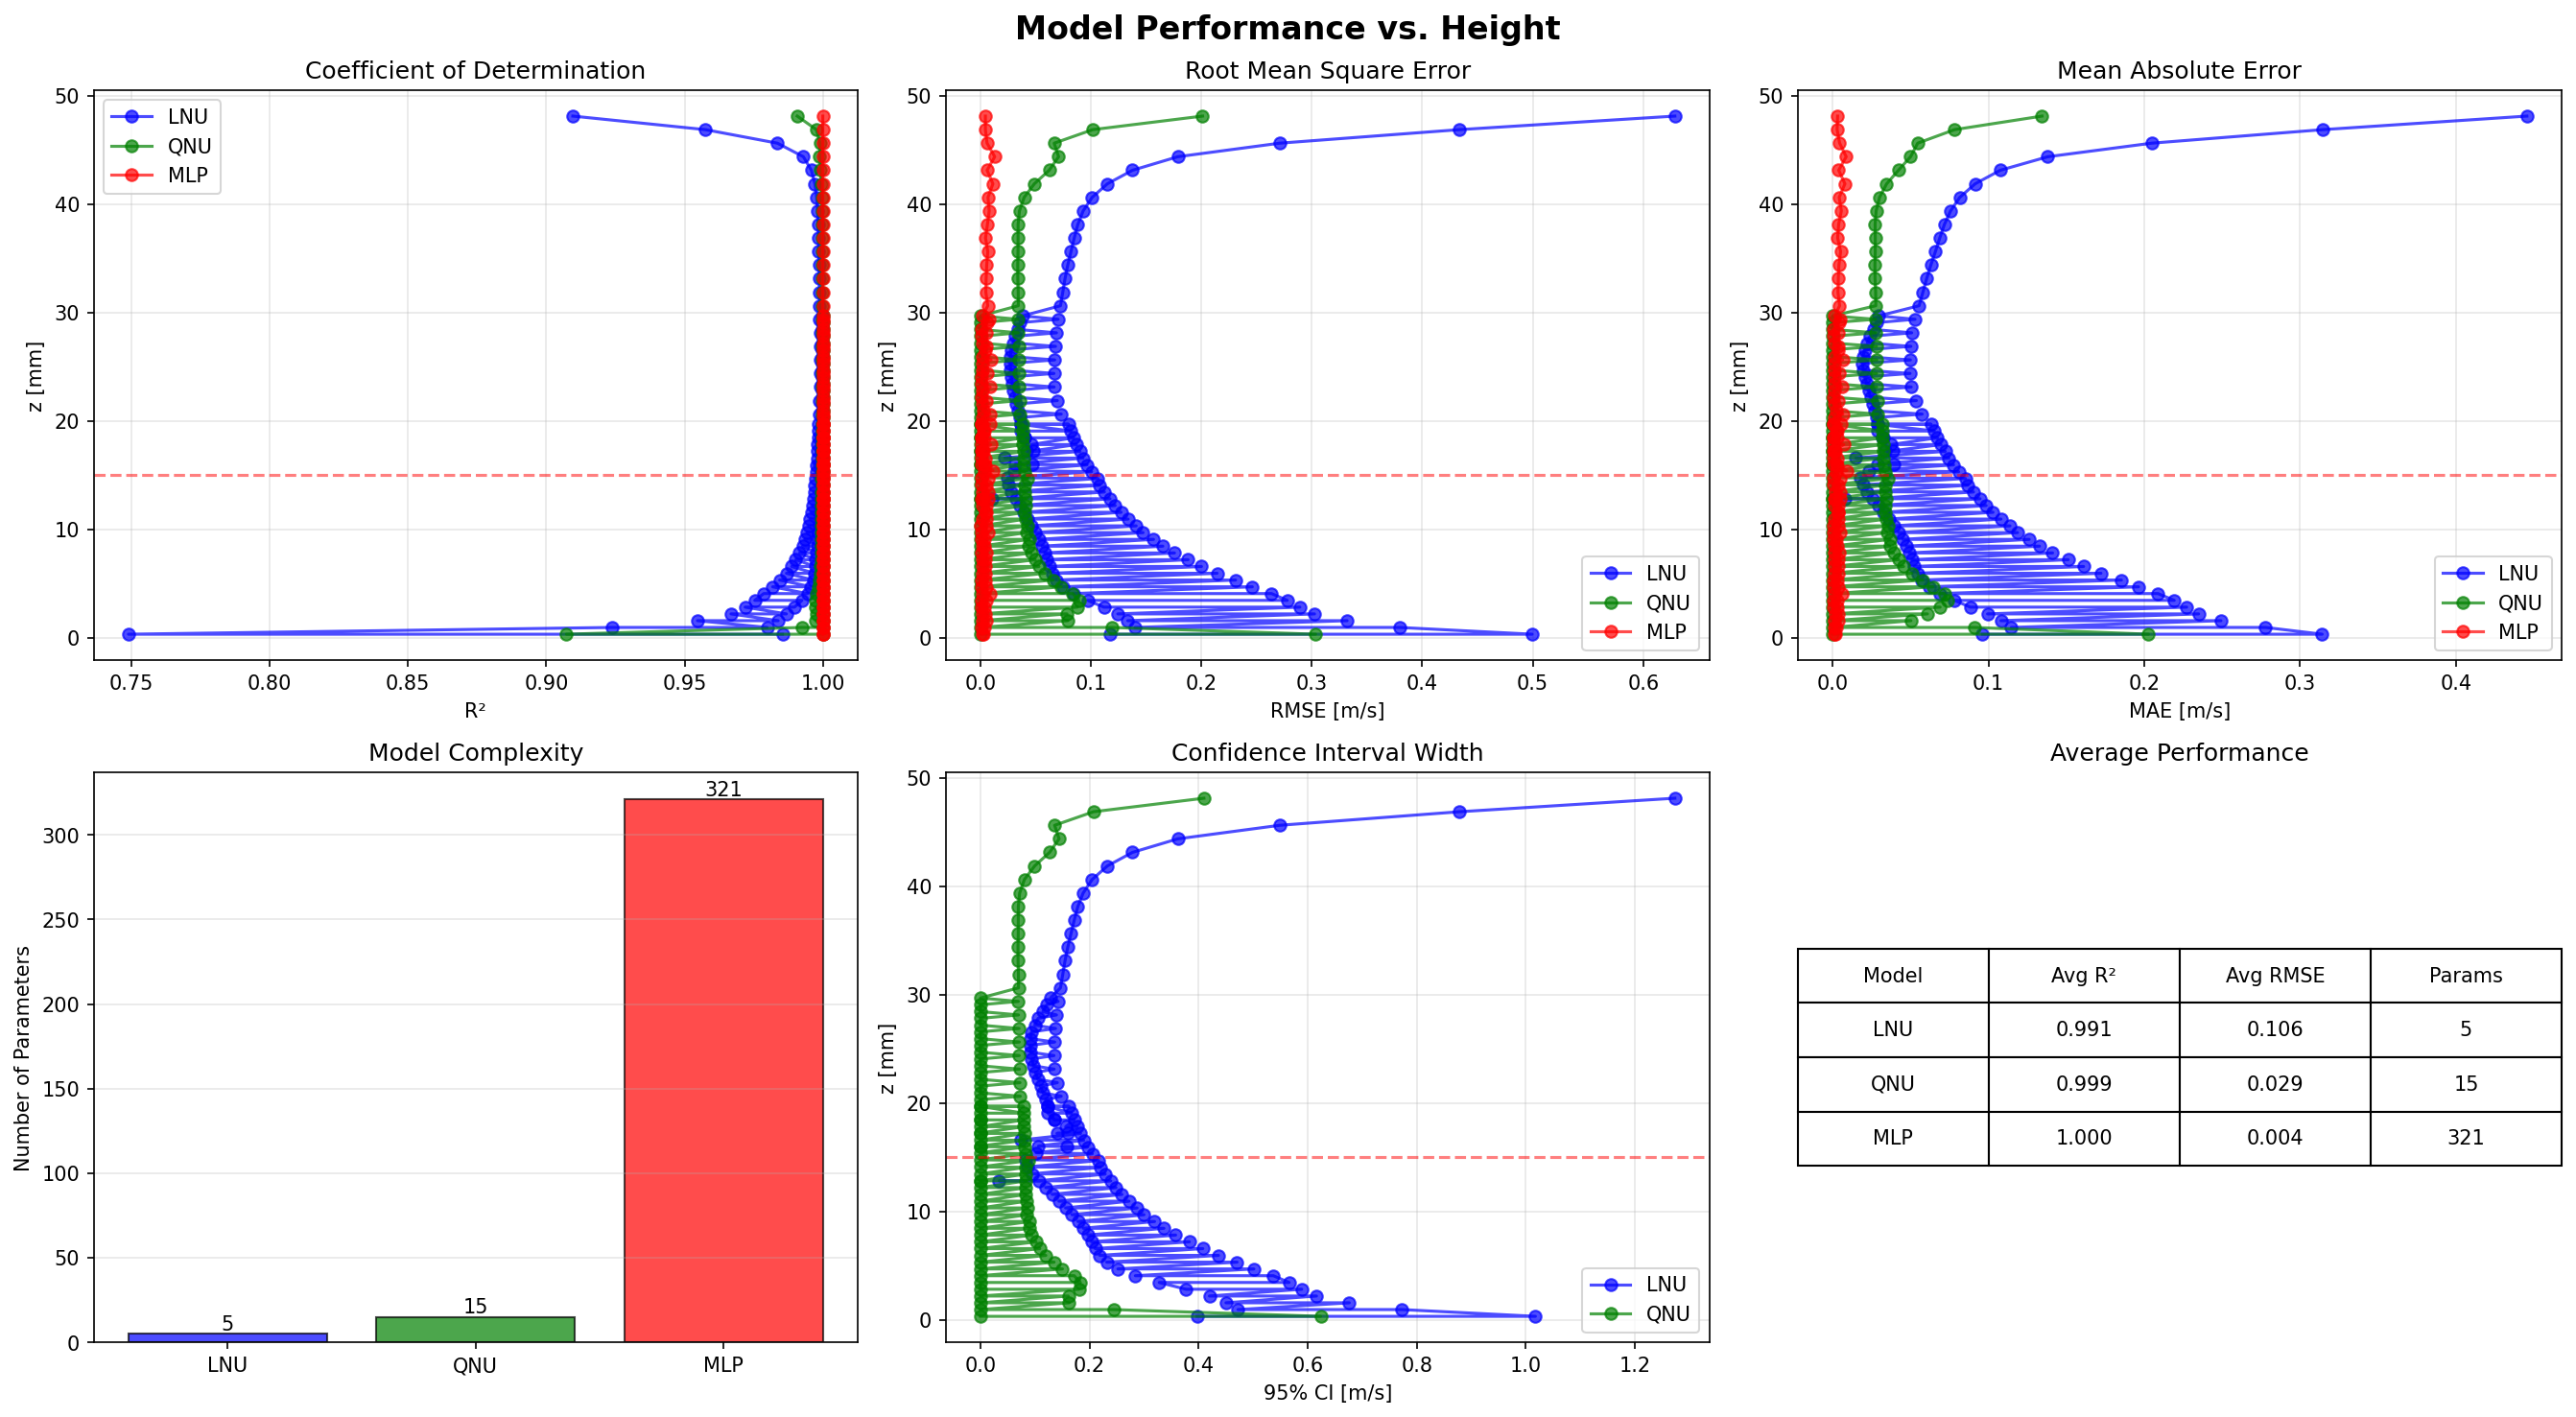

✓ Saved: step3_1_performance_by_height.png


In [12]:
# ============================================================================
# VISUALIZATION 1: METRICS BY HEIGHT
# ============================================================================

print(f"\n{'='*80}")
print("CREATING VISUALIZATIONS")
print("="*80)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Performance vs. Height', fontsize=16, fontweight='bold')

# R² by height
ax = axes[0, 0]
for model_name, color in [('LNU', 'blue'), ('QNU', 'green'), ('MLP', 'red')]:
    R2_vals = [metrics[z][model_name]['R2'] for z in z_heights]
    ax.plot(R2_vals, z_heights*1000, '-o', label=model_name, color=color, alpha=0.7)
ax.set_xlabel('R²')
ax.set_ylabel('z [mm]')
ax.set_title('Coefficient of Determination')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(H_CUBE*1000, color='red', linestyle='--', alpha=0.5, label='Cube height')

# RMSE by height
ax = axes[0, 1]
for model_name, color in [('LNU', 'blue'), ('QNU', 'green'), ('MLP', 'red')]:
    RMSE_vals = [metrics[z][model_name]['RMSE'] for z in z_heights]
    ax.plot(RMSE_vals, z_heights*1000, '-o', label=model_name, color=color, alpha=0.7)
ax.set_xlabel('RMSE [m/s]')
ax.set_ylabel('z [mm]')
ax.set_title('Root Mean Square Error')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(H_CUBE*1000, color='red', linestyle='--', alpha=0.5)

# MAE by height
ax = axes[0, 2]
for model_name, color in [('LNU', 'blue'), ('QNU', 'green'), ('MLP', 'red')]:
    MAE_vals = [metrics[z][model_name]['MAE'] for z in z_heights]
    ax.plot(MAE_vals, z_heights*1000, '-o', label=model_name, color=color, alpha=0.7)
ax.set_xlabel('MAE [m/s]')
ax.set_ylabel('z [mm]')
ax.set_title('Mean Absolute Error')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(H_CUBE*1000, color='red', linestyle='--', alpha=0.5)

# Number of parameters
ax = axes[1, 0]
model_names = ['LNU', 'QNU', 'MLP']
n_params = [metrics[z_heights[0]][name]['n_params'] for name in model_names]
colors = ['blue', 'green', 'red']
bars = ax.bar(model_names, n_params, color=colors, alpha=0.7, edgecolor='black')
ax.set_ylabel('Number of Parameters')
ax.set_title('Model Complexity')
ax.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}', ha='center', va='bottom')

# Confidence intervals (LNU and QNU)
ax = axes[1, 1]
for model_name, color in [('LNU', 'blue'), ('QNU', 'green')]:
    CI_vals = [metrics[z][model_name]['CI'] for z in z_heights]
    ax.plot(CI_vals, z_heights*1000, '-o', label=model_name, color=color, alpha=0.7)
ax.set_xlabel('95% CI [m/s]')
ax.set_ylabel('z [mm]')
ax.set_title('Confidence Interval Width')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(H_CUBE*1000, color='red', linestyle='--', alpha=0.5)

# Summary statistics
ax = axes[1, 2]
summary_data = []
for model_name in ['LNU', 'QNU', 'MLP']:
    R2_mean = np.mean([metrics[z][model_name]['R2'] for z in z_heights])
    RMSE_mean = np.mean([metrics[z][model_name]['RMSE'] for z in z_heights])
    n_params = metrics[z_heights[0]][model_name]['n_params']
    summary_data.append([model_name, f"{R2_mean:.3f}", f"{RMSE_mean:.3f}", f"{n_params}"])

table = ax.table(cellText=summary_data,
                colLabels=['Model', 'Avg R²', 'Avg RMSE', 'Params'],
                cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)
ax.axis('off')
ax.set_title('Average Performance')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'step3_1_performance_by_height.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step3_1_performance_by_height.png")
plt.close()

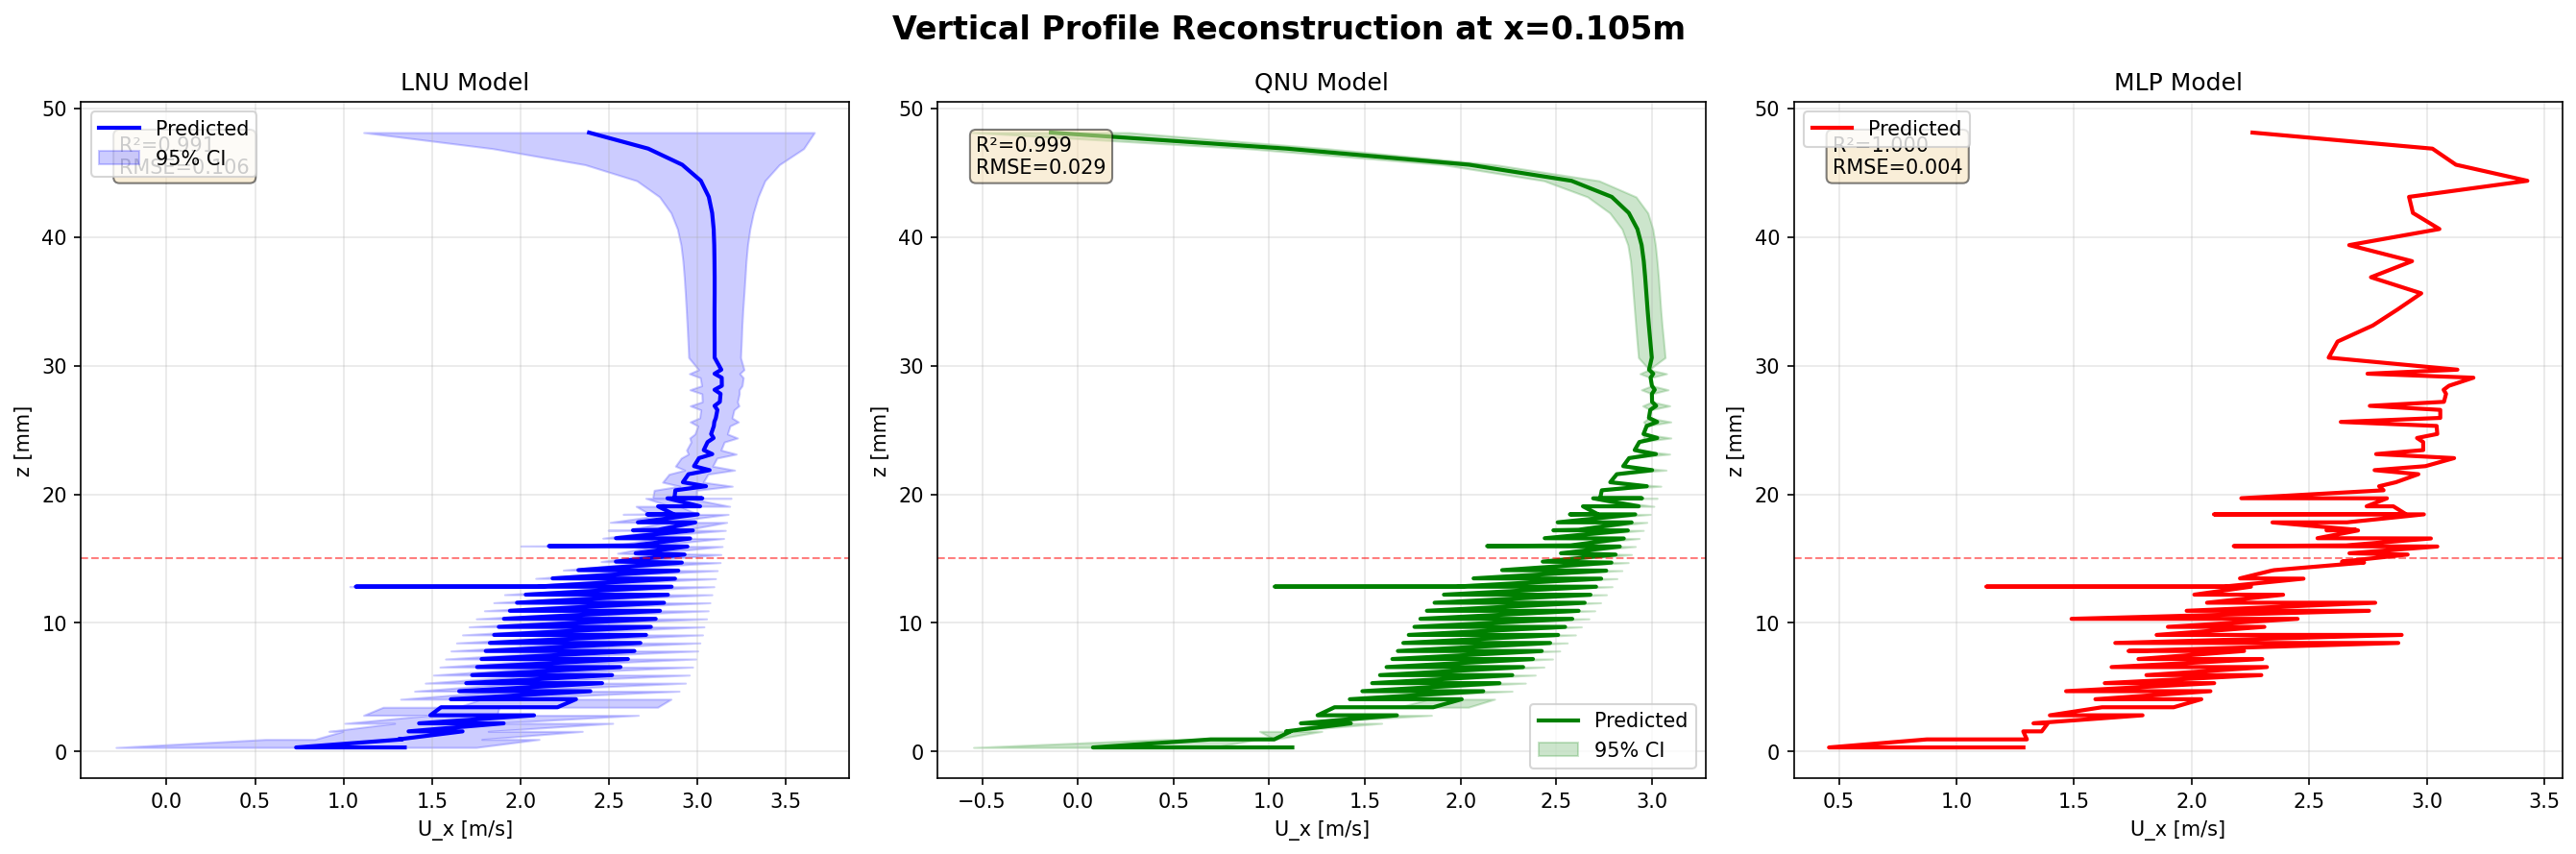

✓ Saved: step3_2_profile_reconstruction.png


In [13]:
# ============================================================================
# VISUALIZATION 2: PROFILE RECONSTRUCTION
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(f'Vertical Profile Reconstruction at x={x_test_loc}m', 
             fontsize=16, fontweight='bold')

for ax, model_name, color in zip(axes, ['LNU', 'QNU', 'MLP'], 
                                  ['blue', 'green', 'red']):
    # Plot predicted profile
    ax.plot(profiles_predicted[model_name], z_heights*1000, 
            '-', color=color, linewidth=2, label='Predicted')
    
    # Add confidence interval for LNU and QNU
    if model_name in ['LNU', 'QNU']:
        CI_vals = [metrics[z][model_name]['CI'] for z in z_heights]
        U_lower = np.array(profiles_predicted[model_name]) - np.array(CI_vals)
        U_upper = np.array(profiles_predicted[model_name]) + np.array(CI_vals)
        ax.fill_betweenx(z_heights*1000, U_lower, U_upper, 
                        color=color, alpha=0.2, label='95% CI')
    
    ax.axhline(H_CUBE*1000, color='red', linestyle='--', alpha=0.5, linewidth=1)
    ax.set_xlabel('U_x [m/s]')
    ax.set_ylabel('z [mm]')
    ax.set_title(f'{model_name} Model')
    ax.grid(True, alpha=0.3)
    ax.legend()
    
    # Add performance text
    R2_avg = np.mean([metrics[z][model_name]['R2'] for z in z_heights])
    RMSE_avg = np.mean([metrics[z][model_name]['RMSE'] for z in z_heights])
    ax.text(0.05, 0.95, f'R²={R2_avg:.3f}\nRMSE={RMSE_avg:.3f}',
            transform=ax.transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'step3_2_profile_reconstruction.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: step3_2_profile_reconstruction.png")
plt.close()

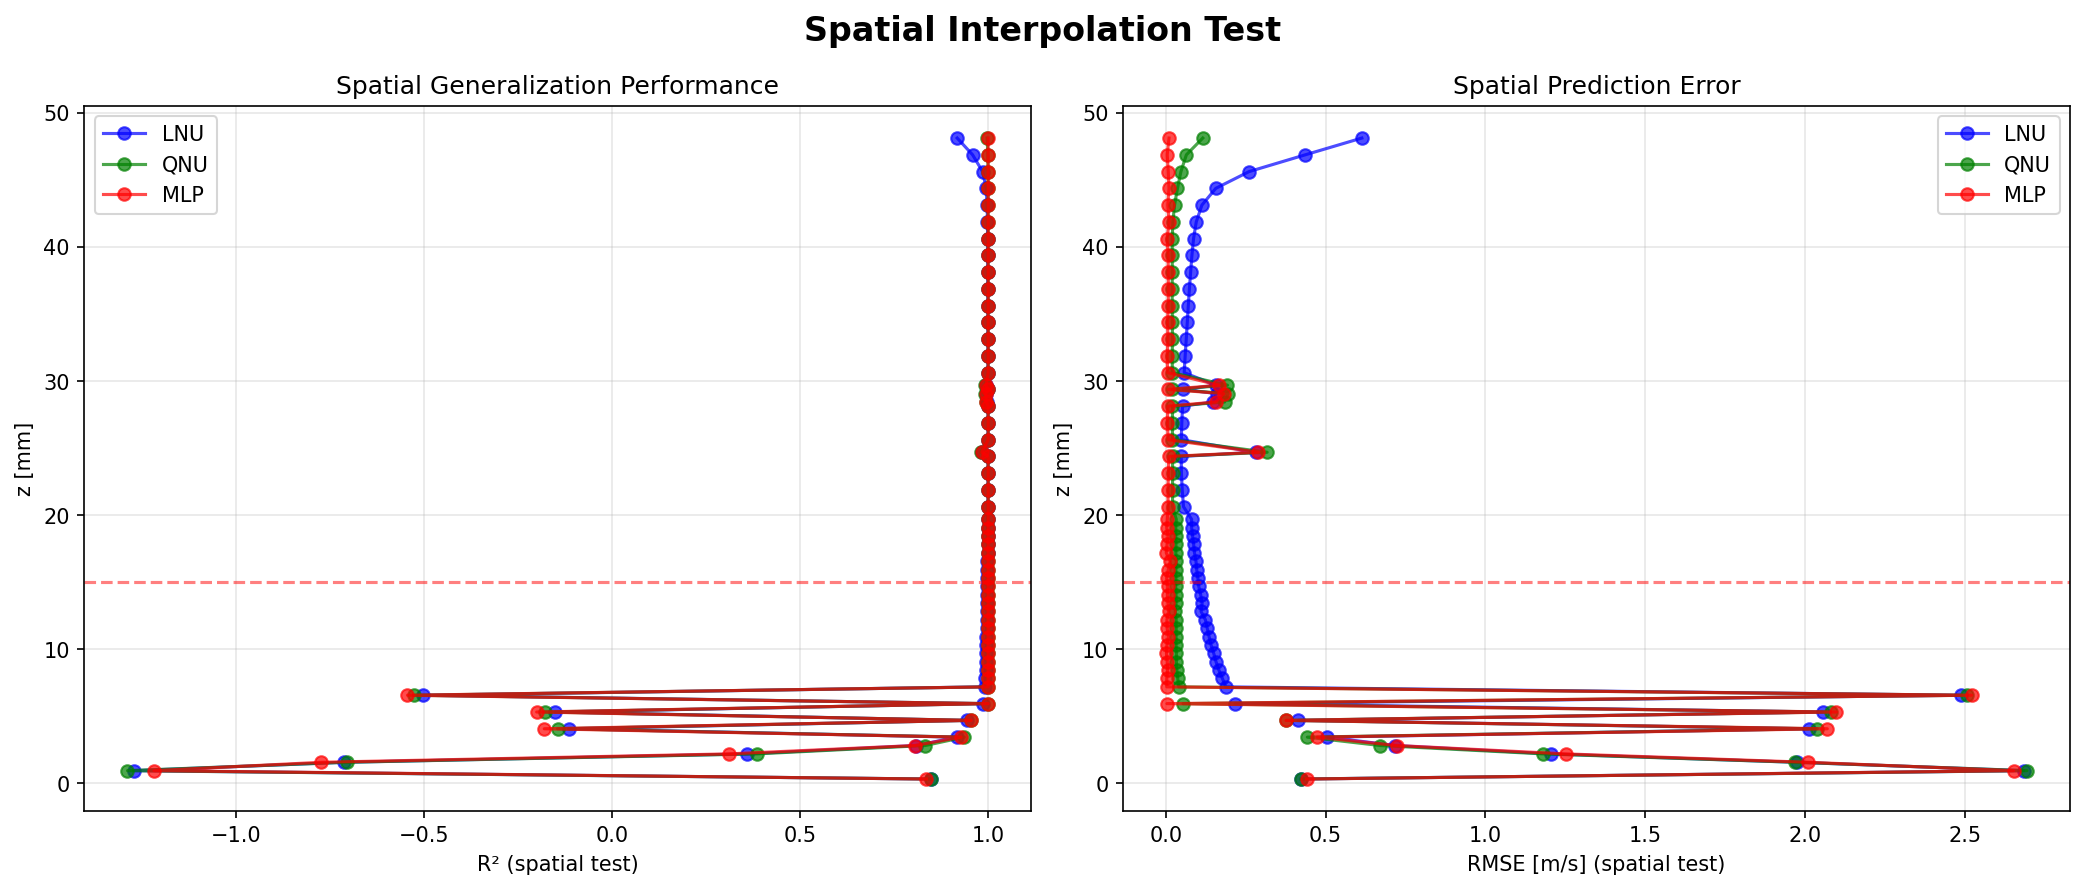

✓ Saved: step3_3_spatial_test.png


In [14]:
# ============================================================================
# VISUALIZATION 3: SPATIAL TEST (if applicable)
# ============================================================================

if VALIDATION_MODE == 'spatial' and len(x_test) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('Spatial Interpolation Test', fontsize=16, fontweight='bold')
    
    # R² for spatial test
    ax = axes[0]
    for model_name, color in [('LNU', 'blue'), ('QNU', 'green'), ('MLP', 'red')]:
        z_vals = [m['z']*1000 for m in spatial_metrics[model_name]]
        R2_vals = [m['R2'] for m in spatial_metrics[model_name]]
        ax.plot(R2_vals, z_vals, '-o', label=model_name, color=color, alpha=0.7)
    ax.set_xlabel('R² (spatial test)')
    ax.set_ylabel('z [mm]')
    ax.set_title('Spatial Generalization Performance')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.axhline(H_CUBE*1000, color='red', linestyle='--', alpha=0.5)
    
    # RMSE for spatial test
    ax = axes[1]
    for model_name, color in [('LNU', 'blue'), ('QNU', 'green'), ('MLP', 'red')]:
        z_vals = [m['z']*1000 for m in spatial_metrics[model_name]]
        RMSE_vals = [m['RMSE'] for m in spatial_metrics[model_name]]
        ax.plot(RMSE_vals, z_vals, '-o', label=model_name, color=color, alpha=0.7)
    ax.set_xlabel('RMSE [m/s] (spatial test)')
    ax.set_ylabel('z [mm]')
    ax.set_title('Spatial Prediction Error')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.axhline(H_CUBE*1000, color='red', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'step3_3_spatial_test.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Saved: step3_3_spatial_test.png")
    plt.close()

In [15]:
# ============================================================================
# SAVE RESULTS
# ============================================================================

print(f"\n{'='*80}")
print("SAVING RESULTS")
print("="*80)

results = {
    'models': models,
    'metrics': metrics,
    'z_heights': z_heights,
    'x_train': x_train,
    'x_test': x_test,
    'feature_scaler': feature_scaler,
    'validation_mode': VALIDATION_MODE,
    'inlet_parameters': inlet_parameters,
}

if VALIDATION_MODE == 'spatial':
    results['spatial_metrics'] = spatial_metrics

with open(REPORTS_DIR / 'step3_results.pkl', 'wb') as f:
    pickle.dump(results, f)

print("✓ Saved: step3_results.pkl")


SAVING RESULTS
✓ Saved: step3_results.pkl


In [16]:
# ============================================================================
# FINAL SUMMARY
# ============================================================================

print(f"\n{'='*80}")
print("STEP 3 COMPLETE - SUMMARY")
print("="*80)

print(f"""
APPROACH: Vertical Stratification (Strategy B)
  ✓ One model per z-height ({len(z_heights)} heights)
  ✓ Input: [x, U_ref, alpha_inlet, delta_inlet] (4 features)
  ✓ Training: {len(x_train)} x-locations × {len(inlet_parameters)} cases = {train_points} points per model

MODELS TRAINED:
  ✓ LNU (Linear):    {metrics[z_heights[0]]['LNU']['n_params']} parameters
  ✓ QNU (Quadratic): {metrics[z_heights[0]]['QNU']['n_params']} parameters
  ✓ MLP (Neural):    {metrics[z_heights[0]]['MLP']['n_params']} parameters

PERFORMANCE (averaged over all z-heights):
""")

for model_name in ['LNU', 'QNU', 'MLP']:
    R2_avg = np.mean([metrics[z][model_name]['R2'] for z in z_heights])
    RMSE_avg = np.mean([metrics[z][model_name]['RMSE'] for z in z_heights])
    MAE_avg = np.mean([metrics[z][model_name]['MAE'] for z in z_heights])
    print(f"  {model_name}:")
    print(f"    R²:   {R2_avg:.4f}")
    print(f"    RMSE: {RMSE_avg:.4f} m/s")
    print(f"    MAE:  {MAE_avg:.4f} m/s")

if VALIDATION_MODE == 'spatial' and len(x_test) > 0:
    print(f"\nSPATIAL TEST (on {len(x_test)} held-out locations):")
    for model_name in ['LNU', 'QNU', 'MLP']:
        R2_test = np.mean([m['R2'] for m in spatial_metrics[model_name]])
        RMSE_test = np.mean([m['RMSE'] for m in spatial_metrics[model_name]])
        print(f"  {model_name}: R²={R2_test:.4f}, RMSE={RMSE_test:.4f} m/s")

print(f"""
OUTPUTS:
  ✓ step3_1_performance_by_height.png
  ✓ step3_2_profile_reconstruction.png""")

if VALIDATION_MODE == 'spatial':
    print(f"  ✓ step3_3_spatial_test.png")

print(f"""  ✓ step3_results.pkl
""")

print("="*80)
print("✓ STEP 3 COMPLETE")
print("="*80)


STEP 3 COMPLETE - SUMMARY

APPROACH: Vertical Stratification (Strategy B)
  ✓ One model per z-height (108 heights)
  ✓ Input: [x, U_ref, alpha_inlet, delta_inlet] (4 features)
  ✓ Training: 8 x-locations × 8 cases = 8 points per model

MODELS TRAINED:
  ✓ LNU (Linear):    5 parameters
  ✓ QNU (Quadratic): 15 parameters
  ✓ MLP (Neural):    321 parameters

PERFORMANCE (averaged over all z-heights):

  LNU:
    R²:   0.9914
    RMSE: 0.1056 m/s
    MAE:  0.0822 m/s
  QNU:
    R²:   0.9987
    RMSE: 0.0287 m/s
    MAE:  0.0226 m/s
  MLP:
    R²:   1.0000
    RMSE: 0.0038 m/s
    MAE:  0.0028 m/s

SPATIAL TEST (on 3 held-out locations):
  LNU: R²=0.8447, RMSE=0.3509 m/s
  QNU: R²=0.8484, RMSE=0.2829 m/s
  MLP: R²=0.8455, RMSE=0.2661 m/s

OUTPUTS:
  ✓ step3_1_performance_by_height.png
  ✓ step3_2_profile_reconstruction.png
  ✓ step3_3_spatial_test.png
  ✓ step3_results.pkl

✓ STEP 3 COMPLETE
